# The SNR is a random variable

Detector noise is random. So if the same gravitational wave arrived in two different stretches of noise, would we measure the same SNR? In this lecture we see why the answer is **no**, and in the exercise you check it yourself by simulating the noise.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")   # a harmless warning from LAL
%config InlineBackend.figure_format = 'retina'

from scipy.signal import welch
from pycbc.psd import aLIGOZeroDetHighPower
from pycbc.waveform import get_fd_waveform

PyCBC.libutils: pkg-config call failed, setting NO_PKGCONFIG=1


## 1. The likelihood

Bayes' theorem relates the parameters $\theta$ of a signal to the data $d$:
$$\underbrace{p(\theta \,|\, d)}_{\text{posterior}} = \frac{\overbrace{p(d \,|\, \theta)}^{\text{likelihood}}\; \overbrace{p(\theta)}^{\text{prior}}}{p(d)} .$$

The likelihood $p(d\,|\,\theta)$ is how probable the observed data are for a given $\theta$. We keep the data fixed and vary $\theta$. It is not a probability distribution for $\theta$.

For example, if we measure a quantity $\mu$ once and get $x$, with a Gaussian error $\sigma$, then
$$p(x\,|\,\mu) \propto \exp\!\Big[-\frac{(x - \mu)^2}{2\sigma^2}\Big] ,$$
which is largest at $\mu = x$. GW data work the same way: each frequency bin is a measurement, with an error set by the noise PSD. So the likelihood is determined by the noise.

The likelihood can be used in two ways:
- Frequentist: the parameters are fixed and the data are random. We ask how the result would change if we repeated the experiment. Used to decide whether a detection is real.
- Bayesian: the data are fixed and the parameters are uncertain. We multiply the likelihood by a prior to get the posterior. Used to measure masses and distances of GW events.

### Example: how heavy is this black hole?

The masses of the heavier black holes (`mass1`) observed so far follow a power law that falls steeply with mass, with a peak at about $35\,M_\odot$: most of them are lighter than $40\,M_\odot$. A new detection returns `mass1` $= 90\,M_\odot$. Given these pieces of information, what is the mass of this black hole?

Note that we observe this binary only once. A frequentist would say that $90\,M_\odot$ is the best possible estimator for the true value of `mass1`. A Bayesian would instead conclude that the noise pushed the measurement up and the true mass is lower than $90\,M_\odot$, because it is very unlikely to get $90\,M_\odot$ among black holes that are usually lighter than $40\,M_\odot$.

Let's see the result before the maths:

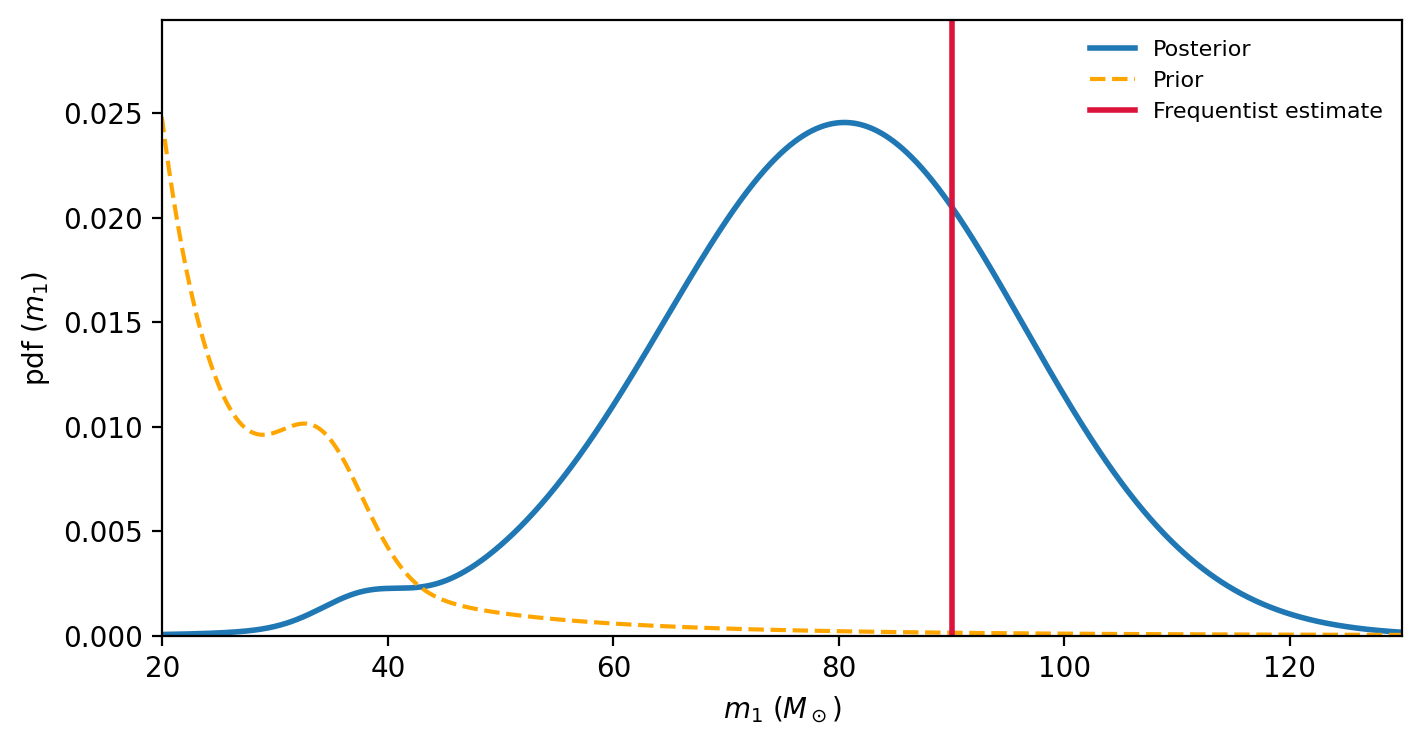

In [2]:
m_obs, sigma = 90, 15                               # measured mass and how noisy the measurement is (Msun)
m = np.linspace(5, 130, 2000)                       # possible true masses (Msun)
dm = m[1] - m[0]

likelihood = np.exp(-0.5 * ((m_obs - m) / sigma) ** 2)
power_law = m ** -3.4
peak = np.exp(-0.5 * ((m - 34) / 4) ** 2)
prior = 0.99 * power_law / (np.sum(power_law) * dm) + 0.01 * peak / (np.sum(peak) * dm)
posterior = likelihood * prior
posterior /= np.sum(posterior) * dm

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(m, posterior, color="C0", lw=2, label=rf"Posterior")
ax.plot(m, prior / prior[m >= 20].max() * posterior.max(), color="orange", ls="--", label="Prior")
ax.set_xlim(20, m[-1])
ax.set_ylim(0, 1.2 * posterior.max())
ax.axvline(m_obs, color="crimson", lw=2, label=rf"Frequentist estimate")
ax.set_xlabel(r"$m_1$ ($M_\odot$)")
ax.set_ylabel(r"pdf ($m_1$)")
ax.legend(fontsize=8, frameon=False)
plt.show()

The end result (skipping over the detailed math) is that the mass of this black hole is not $90\,M_\odot$, but rather about $80\,M_\odot$! More specifically, the Bayesian measurement is $p(61\,M_\odot \le m_1 \le 95\,M_\odot \,|\, m_{1,\rm obs} = 90\,M_\odot) = 0.68$ (i.e. there is a probability of 68% that the mass is between 61 and $95\,M_\odot$). This estimate incorporates not only our measurement, but also the prior information on the black holes observed so far. The small bump at $35\,M_\odot$ comes from the peak in the prior: there is even a small chance that this is one of the many black holes in the peak.

## 3. How to simulate Gaussian noise
A common assumption is that the noise in our data is **gaussian** and that the noise is not correlated across frequency bins. 
Specifically it means that you can imagine the noise being drawn randomly from a gaussian distribution for each frequency. The variance of this Gaussian is set by the PSD $S_n(f)$ 

$$ <|n(f)|^2> \:=\: \frac{1}{2}\:T\: S_n(f) $$

So given the PSD $S_n(f)$ for a segment of duration $T$, the noise in each frequency bin can be simulated as 
$$n(f) = \sqrt{\frac{T\, S_n(f)}{4}}\,\big(x + i\, y\big), \qquad x,\, y \sim \mathcal{N}(0, 1) \text{ (Gaussian distribution centered at 0 with variance 1)}.$$

## 4. Exercise

In this exercise we will compare the **matched filter SNR** for a binary system from two data sets that include different realizations of the noise
$$\rho = \frac{(d|h)}{\sqrt{(h|h)}}.$$
To produce the datasets, we will simulate a waveform and for simplicity inject just the cross polarization into the noise. You can work in the frequency domain, where
$d(f) = n(f)+h(f) $.

Implement the SNR calculation for a binary system with the parameters
- $m_1 = 28 M_\odot$ 
- $m_2 = 28 M_\odot$ 
- $d = 400 \text{ Mpc}$ 


Simulate the noise by drawing randomly from a Gaussian using the official model for the PSD from LIGO.

In [3]:
fs = 4096                  # sampling rate (Hz)
dt = 1 / fs
duration = 32.0            # segment length T (s)
N = int(duration * fs)     # number of samples
t = np.arange(N) * dt
freqs = np.fft.rfftfreq(N, dt)
df = freqs[1] - freqs[0]
f_min, f_max = 20.0, 1000.0

# ---- Model for the PSD in advanced LIGO (zero below 10 Hz) ----
psd = aLIGOZeroDetHighPower(len(freqs), df, 10.0).numpy()

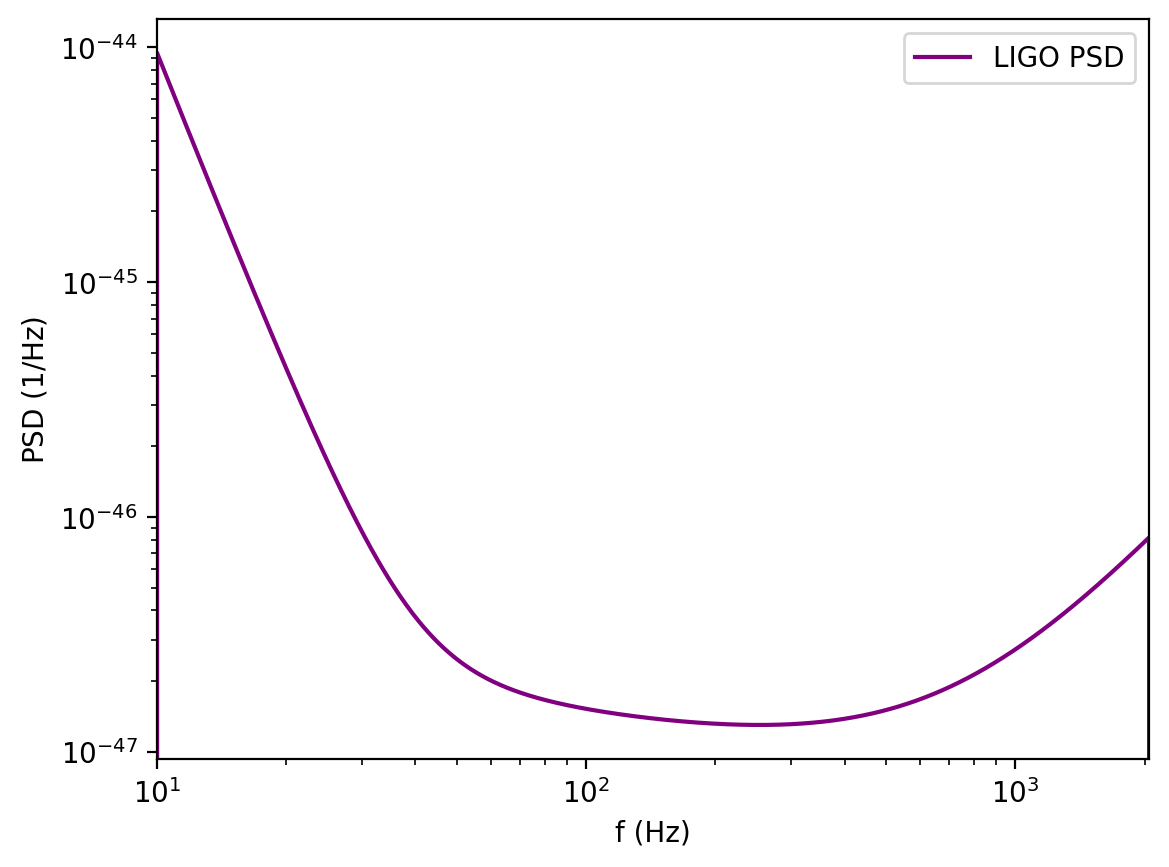

In [4]:
plt.loglog(freqs, psd, color = "purple", label = "LIGO PSD")
plt.xlim(10, fs / 2)
plt.xlabel("f (Hz)")
plt.ylabel(r"PSD ($1/\rm Hz$)")
plt.legend()
plt.show()

In [5]:
# ---- the template: IMRPhenomD, merger at t = 0 ----
hp_fd, hc_fd = get_fd_waveform(approximant="IMRPhenomD", mass1=28, mass2=28, distance=400,delta_f=df, f_lower=f_min, f_final=fs / 2)
template_fd = hp_fd.numpy()

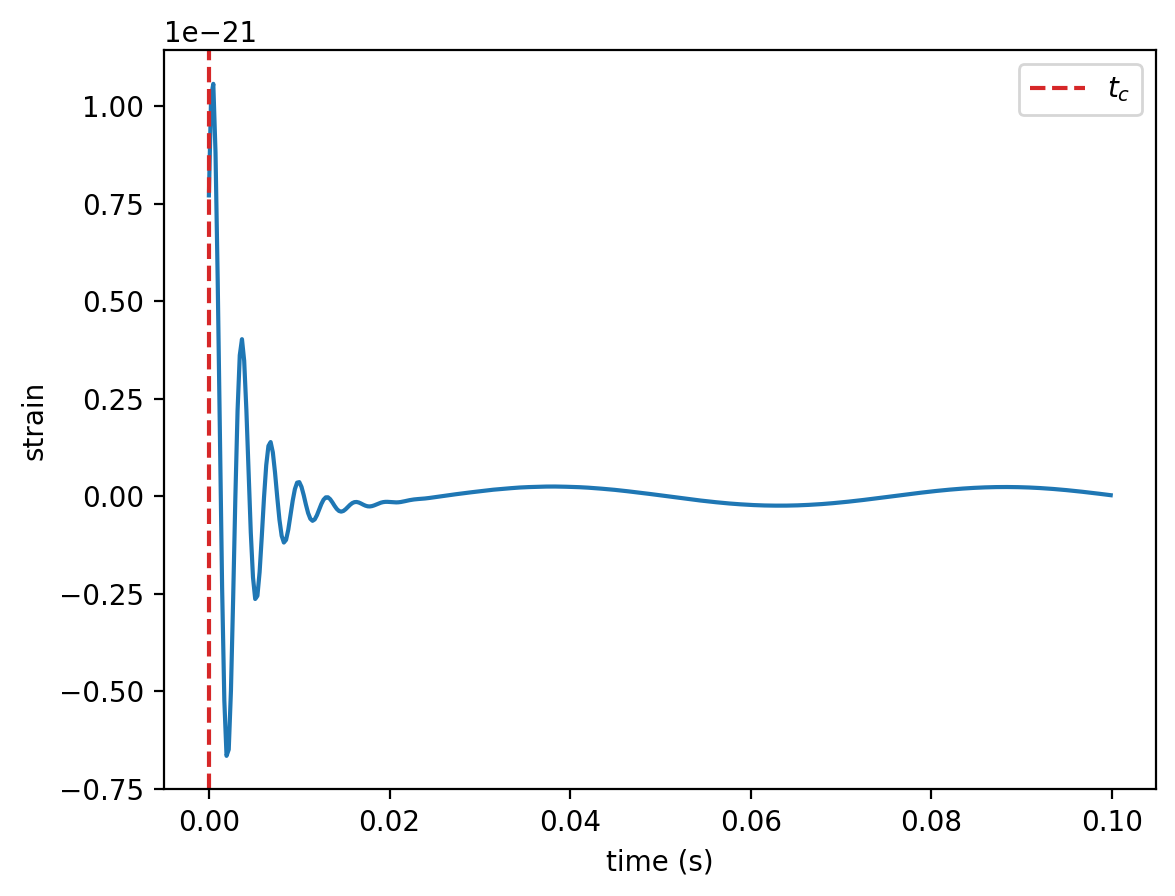

In [6]:
# just for plotting purposes
signal_td = np.fft.irfft(template_fd, n=N)*1/dt # because 1/dt = N*df

t_c = 0
zoom = (t > t_c - 1.0) & (t < t_c + 0.1)
plt.plot(t[zoom], signal_td[zoom])
plt.axvline(t_c, color="C3", ls="--", label=r"$t_c$")
plt.xlabel("time (s)")
plt.ylabel("strain")
plt.legend()
plt.show()

1. **Simulate noise:** Write a function `simulate_noise` that returns one realisation of frequency-domain noise using a random generator from numpy  `np.random.default_rng` and use `.normal(size=...)` for  Gaussian distributed numbers.
2. **Two experiments:** Make two data sets, `d1` and `d2` with two *different* noise realisations, each with the same signal `template_fd` added.
3. Compute matched filter SNR for each

Debugging tipp: Since you divide by the PSD in the inner product, make sure you only use non zero values from your PSD! 

In [7]:
# 1. simulate noise 
def simulate_noise(psd, rng):
    sigma = np.sqrt(duration * psd / 4)
    noise_fd = sigma * (rng.normal(size=len(psd)) + 1j * rng.normal(size=len(psd)))
    return noise_fd

rng = np.random.default_rng(50)

In [8]:
# 2. two experiments: different noise, same signal
d1 = simulate_noise(psd, rng) + template_fd
d2 = simulate_noise(psd, rng) + template_fd

In [9]:
# TODO: implement your snr calculation (you can look back to earlier notebooks)
def inner_prod(a,b,psd):
    return 4*np.real(np.sum(a*np.conjugate(b)/(psd))*df)

def snr(d,h,psd):
    """
    d,h : frequency domain data to go into the inner product
    psd: psd of the noise
    """
    rho = inner_prod(d,h,psd)/(np.sqrt(inner_prod(h,h,psd)))
    return rho

# 3. the SNR of each
rho_1 = snr(d1[psd>0] , template_fd[psd>0], psd[psd>0])
rho_2 = snr(d2[psd>0] , template_fd[psd>0], psd[psd>0])

#  compare
print(f"experiment 1: SNR = {rho_1:.2f}")
print(f"experiment 2: SNR = {rho_2:.2f}")

experiment 1: SNR = 88.70
experiment 2: SNR = 89.71


**Extra:** Estimate the PSD of one realisation with `welch(noise, fs=fs, nperseg=4 * fs)` and plot it on top of `psd`. Do they agree?

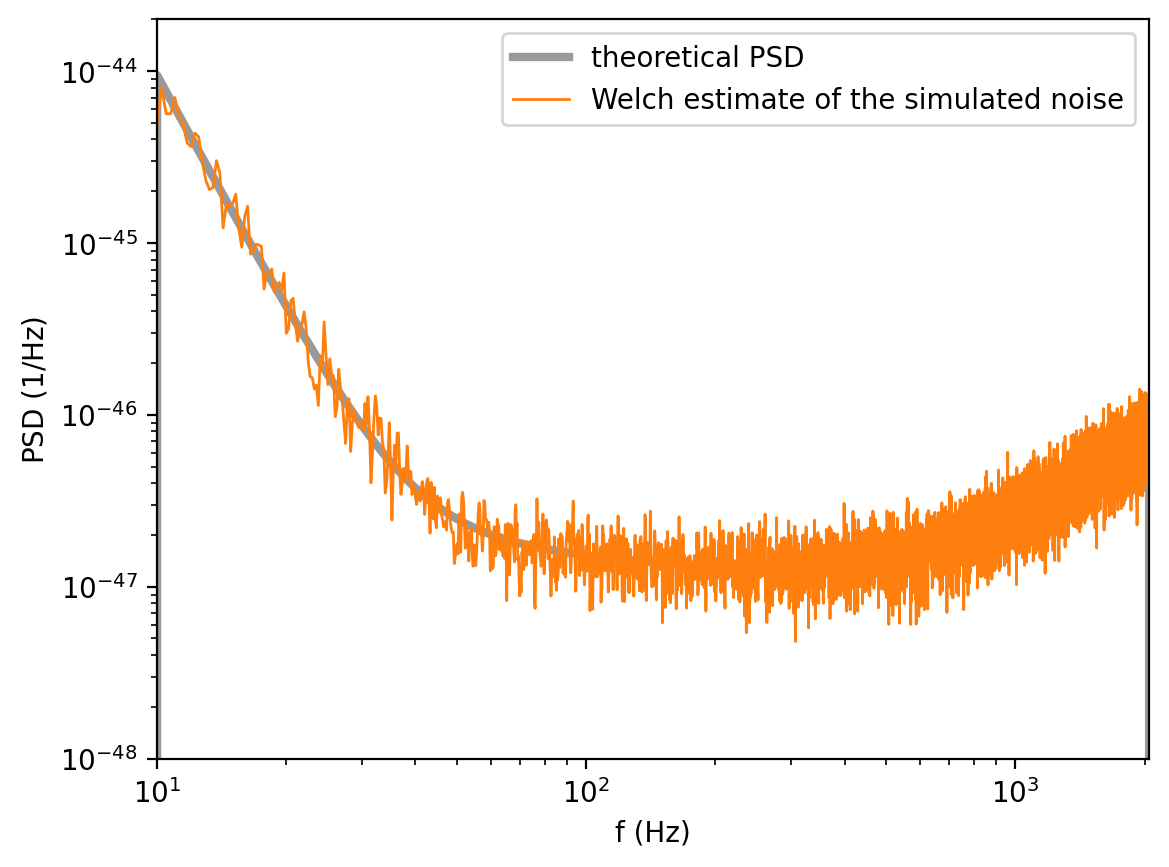

In [10]:
# 2. check the PSD
noise = np.fft.irfft(simulate_noise(psd, rng) / dt, n=N)

f_welch, psd_welch = welch(noise, fs=fs, nperseg=4 * fs)
plt.loglog(freqs, psd, color="0.6", lw=3, label="theoretical PSD")
plt.loglog(f_welch[1:], psd_welch[1:], color="C1", lw=1, label="Welch estimate of the simulated noise")
plt.xlim(10, fs / 2)
plt.ylim(1e-48, 2e-44)
plt.xlabel("f (Hz)")
plt.ylabel(r"PSD ($1/\rm Hz$)")
plt.legend()
plt.show()